# Identifying patients at high risk of fatal coronary heart disease (CHD), or hospitalization due to myocardial infarction (MI)

This project develops a classification model to predict patients at high risk for fatal coronary heart disease, or hospitalization due to myocardial infarction (heart attack) on the basis of a patient's background characteristics. Because death or hospitalization is a binary outcome, I use logistic regression to estimate probability of heart attack hospitalization; code is adapted from Lecture 3. Finally, I evaluate the model using confusion matrix, ROC, and AUC.

### Setup

In [1]:
import os, sys, ast

# set working directory: runs locally, or in Google Colab with data.csv in MyDrive/15.071_project1
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/15.071_project1"
else:
    PROJECT_DIR = r"C:\Users\Joseph\Desktop\ai-edge\Project1"
os.chdir(PROJECT_DIR)
print("Working directory: ", os.getcwd())

#load packages
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import confusion_matrix, auc
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

Mounted at /content/drive
Working directory:  /content/drive/MyDrive/15.071_project1


### The Framingham Heart Study dataset

The Framingham Heart Study is a long term prospective cohort study of risk factors for coronary heart disease, among a population of participants in Framingham, Massachusetts ([reference](https://biolincc.nhlbi.nih.gov/media/teachingstudies/FHS_Teaching_Longitudinal_Data_Documentation_2021a.pdf?link_time=2024-05-26_10:36:20.705109)). The dataset used in this project is derived from the original Framingham Heart Study, but modified and anonymized for teaching purposes; therefore it is inappropriate for use in publication. This dataset includes 1738 participants over a period of 8 years, assessing for outcomes including angina, myocardial infarction (heart attack), atherothrombotic infarction, stroke, and death between cohort entry and follow up at 8 years.

The target prediction variable is "mi_fchd" defined as Hospitalized Myocardial Infarction (heart attack) or Fatal Coronary Heart Disease, where ‘0' indicates no occurrence during followup, and ‘1' indicates occurrence during followup. I chose this variable instead of "hospmi" defined as Hospitalized Myocardial Infarction alone, because my prediction model identifies patients at highest risk of severe cardiac disease, which I define as death due to heart disease, or hospitalization due to heart attack.

Features in this model are described below, with values obtained at the time of cohort entry:
- sex: 1 indicates male, 2 indicates female
- totchol: serum total cholesterol in mg/dL
- age: age in years
- sysbp and diabp: systolic and diastolic blood pressures in mmHg
- cursmoke: current cigarette smoking. 0 indicates non-current smoker, 1 indicates current smoker
- cigpday: number of cigarettes smoked each day
- bmi: body mass index in kg/m^2
- diabetes: diabetes present. 0 indicates non-diabetic, 1 indicates diabetic
- bpmeds: use of anti-hypertensive medication. 0 indicates non-current use, 1 indicates current use
- heartrte: heart rate in beats/min
- glucose: serum glucose in mg/dL
- educ: educational attainment. 1 indicates no high school diploma, 2 indicates high school diploma or GED, 3 indicates some college or vocational school, 4 indicates college degree or more
- prevchd: prevalent coronary heart disease (angina pectoris, myocardial infarction, coronary insufficiency). 0 indicates free of disease, 1 indicates prevalent disease
- prevap: prevalent angina pectoris. 0 indicates free of disease, 1 indicates prevalent disease
- prevmi: prevalent myocardial infarction. 0 indicates free of disease, 1 indicates prevalent disease
- prevstrk: prevalent stroke. 0 indicates free of disease, 1 indicates prevalent disease

Features I exclude include:
- randid: unique participant identifier
- prevhyp: prevalent hypertension defined as being treated for hypertension, or if blood pressure exceeded 140/90. 0 indicates free of disease, 1 indicates prevalent disease. I will exclude this feature due to multicollinearity with sysbp, diabp, and bpmeds.

For reference, other labels in the dataset include:
- death: death from any cause
- angina: angina pectoris
- hospmi: hospitalized myocardial infarction
- anychd: angina pectoris, myocardial infarction, coronary insufficiency, or fatal coronary heart disease
- stroke: atherothrombotic infarction, cerebral embolism, intracerebral hemorrhage, subarachnoid hemorrhage, or fatal cerebrovascular disease
- cvd: a composite of anychd and stroke, excluding angina pectoris and coronary insufficiency

In [2]:
#load dataframe
framingham = pd.read_csv("data.csv")

#stop truncations
pd.set_option('display.max_columns', None)

#display data
framingham.info(verbose=True, show_counts=True)
display(framingham.head(4))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1738 entries, 0 to 1737
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   randid    1738 non-null   int64  
 1   sex       1738 non-null   int64  
 2   totchol   1722 non-null   float64
 3   age       1738 non-null   int64  
 4   sysbp     1738 non-null   float64
 5   diabp     1738 non-null   float64
 6   cursmoke  1738 non-null   int64  
 7   cigpday   1725 non-null   float64
 8   bmi       1738 non-null   float64
 9   diabetes  1738 non-null   int64  
 10  bpmeds    1711 non-null   float64
 11  heartrte  1738 non-null   int64  
 12  glucose   1587 non-null   float64
 13  educ      1699 non-null   float64
 14  prevchd   1738 non-null   int64  
 15  prevap    1738 non-null   int64  
 16  prevmi    1738 non-null   int64  
 17  prevstrk  1738 non-null   int64  
 18  prevhyp   1738 non-null   int64  
 19  death     1738 non-null   int64  
 20  angina    1738 non-null   int6

,randid,sex,totchol,age,sysbp,diabp,cursmoke,cigpday,bmi,diabetes,bpmeds,heartrte,glucose,educ,prevchd,prevap,prevmi,prevstrk,prevhyp,death,angina,hospmi,mi_fchd,anychd,stroke,cvd
0,2448,1,195.0,39,106.0,70.0,0,0.0,26.969999,0,0.0,80,77.0,4.0,0,0,0,0,0,0,0,1,1,1,0,1
1,6238,2,250.0,46,121.0,81.0,0,0.0,28.730000,0,0.0,95,76.0,2.0,0,0,0,0,0,0,0,0,0,0,0,0
2,9428,1,245.0,48,127.5,80.0,1,20.0,25.340000,0,0.0,75,70.0,1.0,0,0,0,0,0,0,0,0,0,0,0,0
3,10552,2,225.0,61,150.0,95.0,1,30.0,28.580000,0,0.0,65,103.0,3.0,0,0,0,0,1,1,0,0,0,0,1,1


### Univariate exploratory data analysis
In this section, I visualize the outcome as a function of each of the model's features, to develop an intuition about which features might be most important. At first glance, male sex, diabetes,  prevalent coronary heart disease, prevalent angina pectoris, and prevalent myocardial infarction seem to yield a discriminatory split.

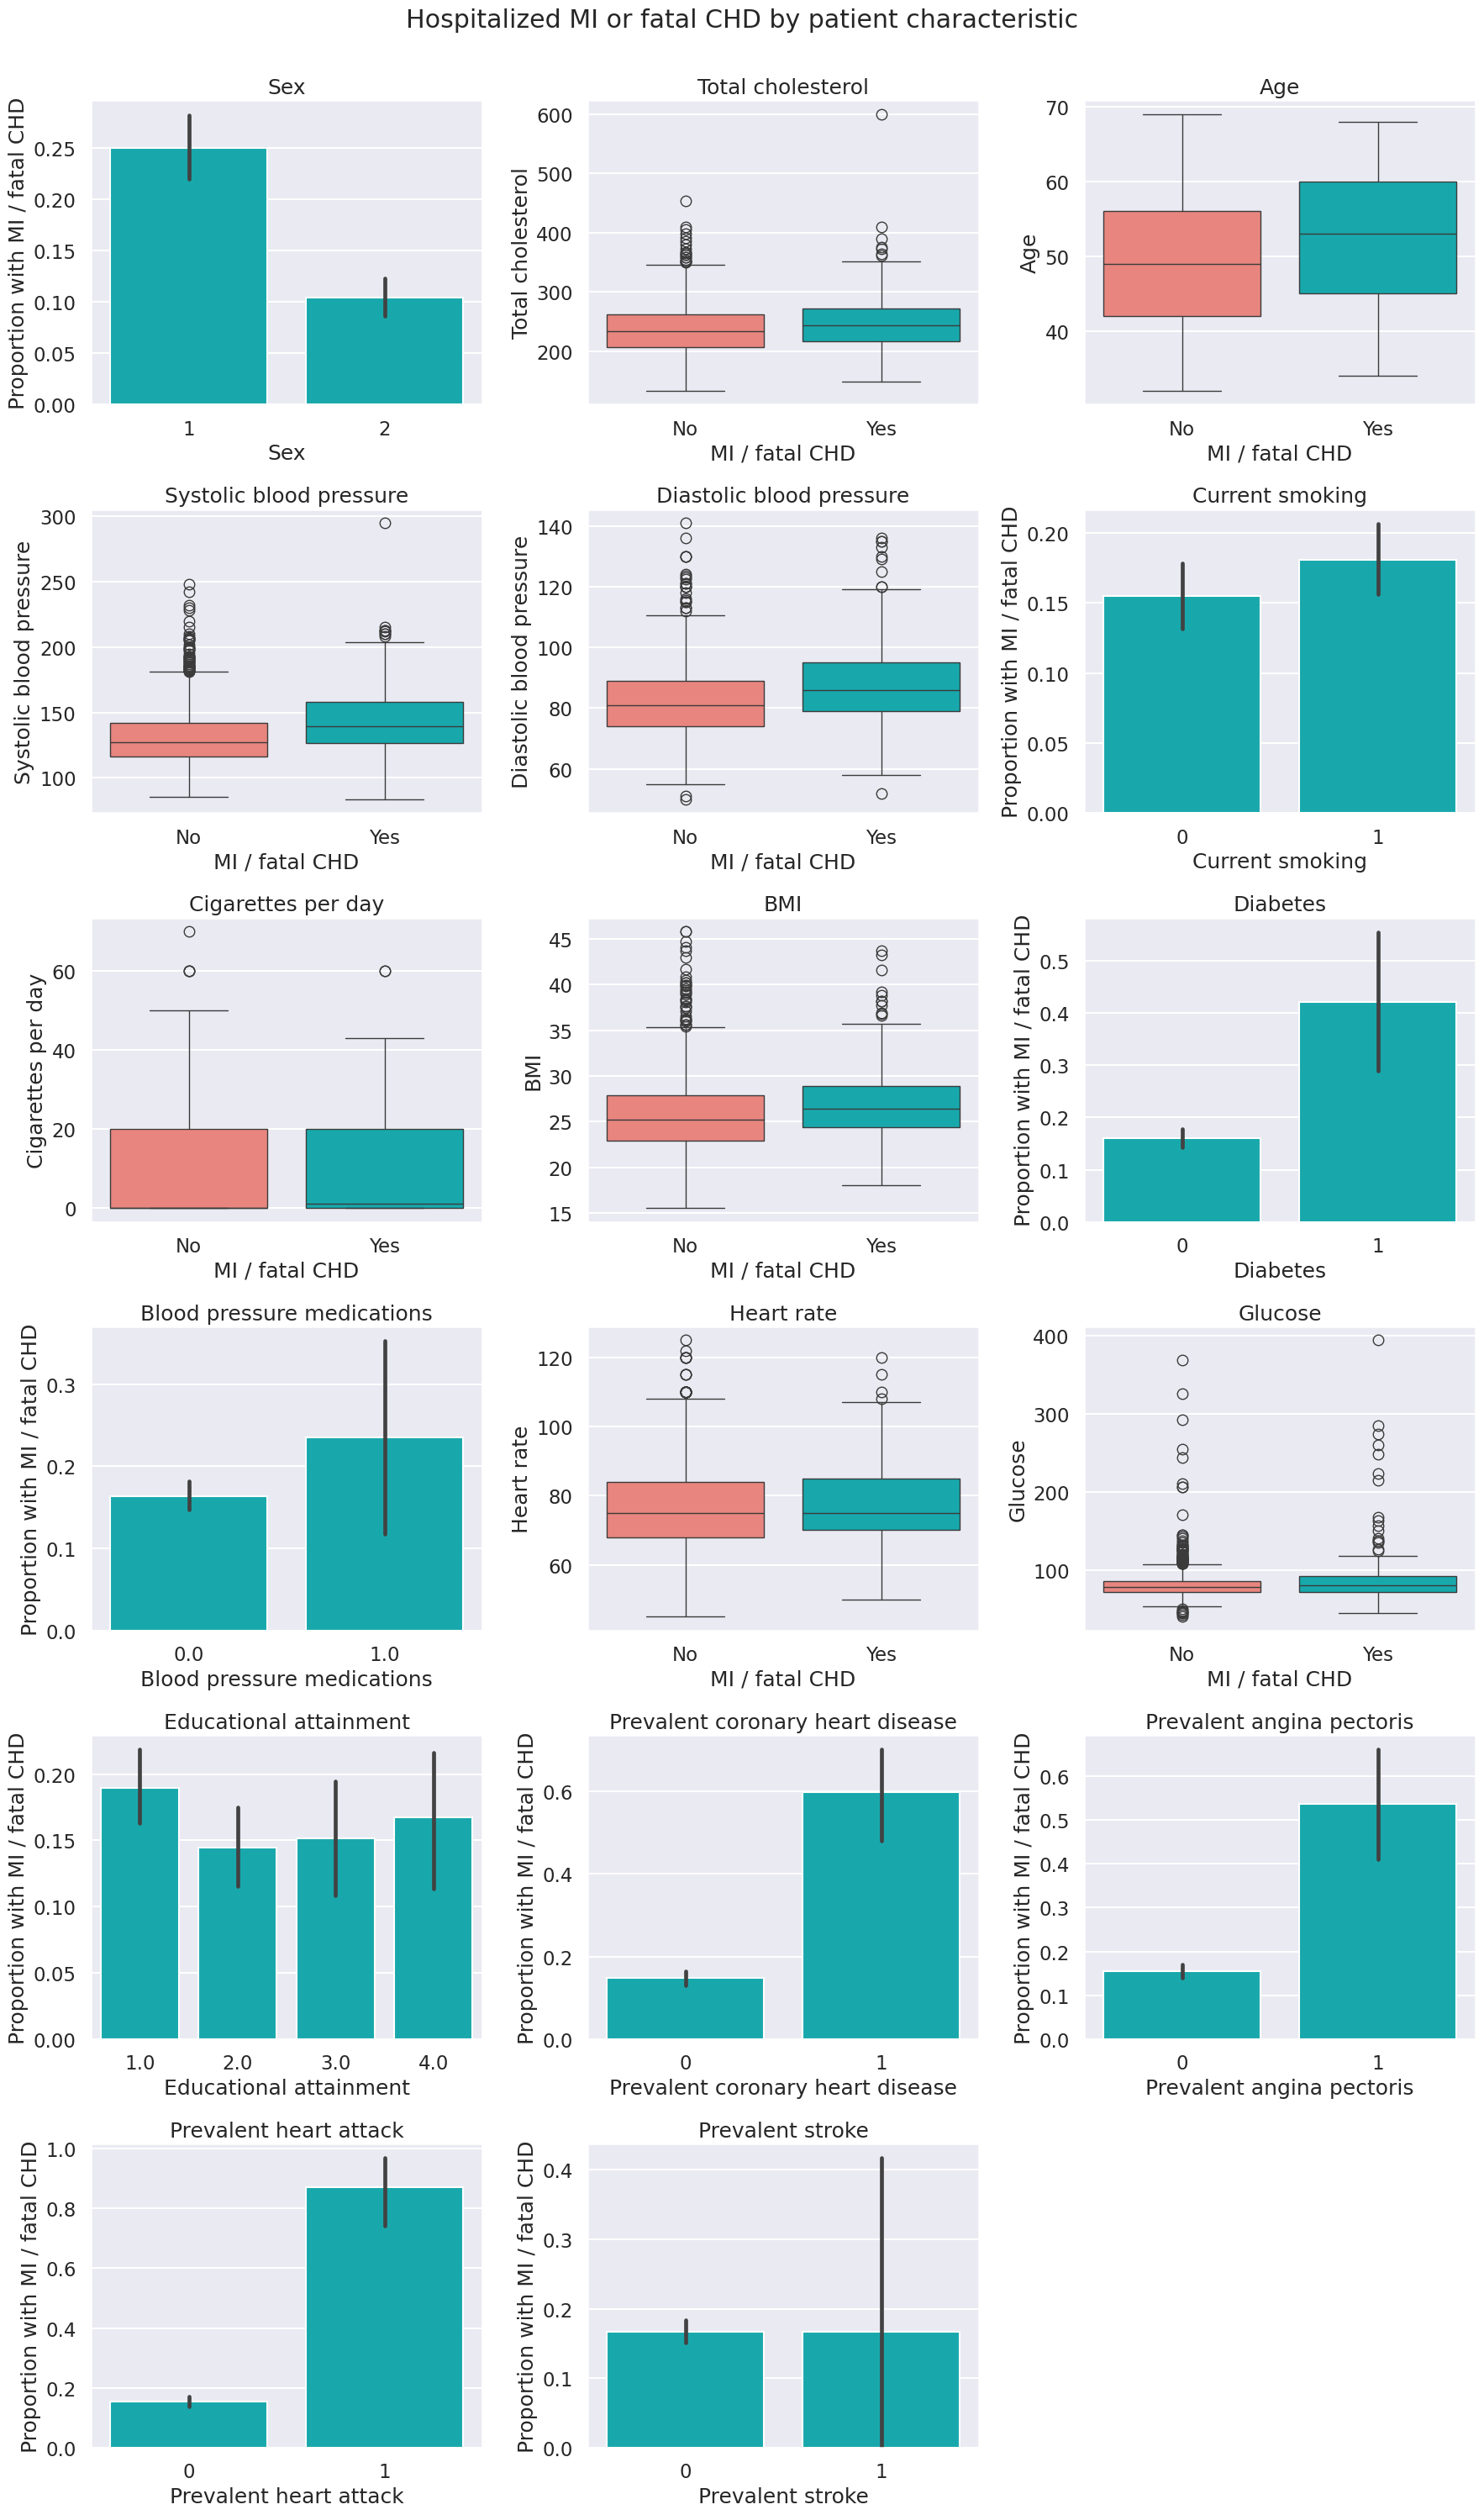

In [3]:
# Set the plotting style
sns.set_style("darkgrid")
sns.set_context("talk")

# Variables to visualize (variable name, axis label)
variables = [
    ("sex", "Sex"),
    ("totchol", "Total cholesterol"),
    ("age", "Age"),
    ("sysbp", "Systolic blood pressure"),
    ("diabp", "Diastolic blood pressure"),
    ("cursmoke", "Current smoking"),
    ("cigpday", "Cigarettes per day"),
    ("bmi", "BMI"),
    ("diabetes", "Diabetes"),
    ("bpmeds", "Blood pressure medications"),
    ("heartrte", "Heart rate"),
    ("glucose", "Glucose"),
    ("educ", "Educational attainment"),
    ("prevchd", "Prevalent coronary heart disease"),
    ("prevap", "Prevalent angina pectoris"),
    ("prevmi", "Prevalent heart attack"),
    ("prevstrk", "Prevalent stroke")
]

# Label the target explicitly so that each color is tied to its own category
df = framingham.assign(MI_FCHD=framingham["mi_fchd"].map({0: "No", 1: "Yes"}))
palette = {"Yes": "#00BFC4", "No": "#F8766D"}

categorical = {"sex", "cursmoke", "diabetes", "bpmeds", "educ",
               "prevchd", "prevap", "prevmi", "prevstrk"}

ncols = 3
nrows = -(-len(variables) // ncols)   # ceiling division -> 6
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = axes.flatten()

for ax, (var, label) in zip(axes, variables):
    if var in categorical:
        # share of patients with the outcome in each category
        sns.barplot(data=framingham, x=var, y="mi_fchd", ax=ax,
                    color="#00BFC4", errorbar=("ci", 95))
        ax.set_ylabel("Proportion with MI / fatal CHD")
    else:
        # distribution of the variable split by outcome
        sns.boxplot(data=df, x="MI_FCHD", y=var, hue="MI_FCHD",
                    palette=palette, order=["No", "Yes"], legend=False, ax=ax)
        ax.set_ylabel(label)
        ax.set_xlabel("MI / fatal CHD")
    ax.set_title(label)
    if var in categorical:
        ax.set_xlabel(label)

# hide unused subplot(s)
for ax in axes[len(variables):]:
    ax.set_visible(False)

fig.suptitle("Hospitalized MI or fatal CHD by patient characteristic", y=1.0)
plt.tight_layout()
plt.show()

### Training and testing split
Before splitting data, remove rows with null values so they don't cause errors later on. Each row represents a unique participant, so the data can be split row-by-row without the need to account for repeated observations.

In [4]:
features = ['sex','totchol','age','sysbp','diabp','cursmoke','cigpday','bmi','diabetes','bpmeds','heartrte','glucose',
    'educ','prevchd','prevap','prevmi','prevstrk']
framingham = framingham[features + ['mi_fchd']].dropna()

X = framingham.drop("mi_fchd", axis=1)
y = framingham["mi_fchd"]

# Split: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1234, stratify=y)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


Train size: 1057
Test size: 453


In the training data, the proportion of MI requiring hospitalization or fatal CHD is 17%. At baseline, predicting no MI requiring hospitalization or fatal CHD would result in 83% accuracy; therefore the accuracy for the ML model should exceed the 83% that would be achieved by guessing only NO fatal CHD or MI requiring hospitalization.

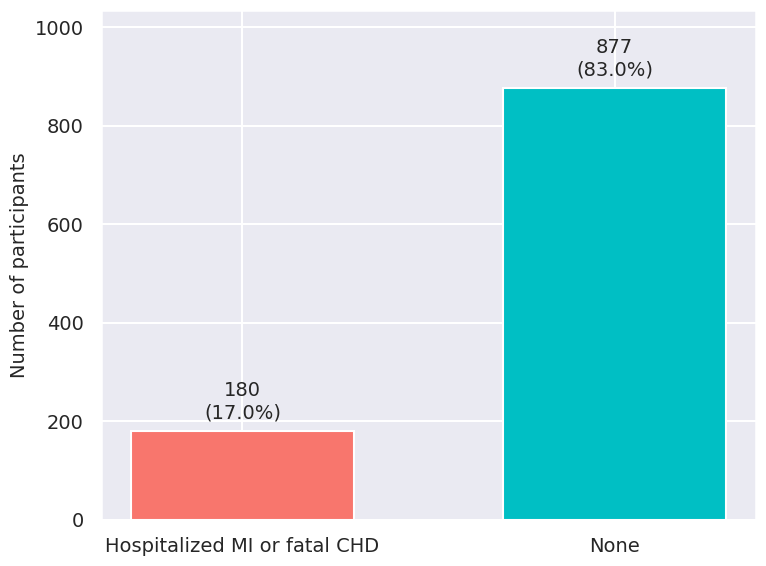

In [5]:
number_of_mi_fchd = y_train.sum()
number_of_no_mi_fchd = len(y_train) - number_of_mi_fchd

counts = [number_of_mi_fchd, number_of_no_mi_fchd]
labels = ["Hospitalized MI or fatal CHD", "None"]
colors = ["#F8766D", "#00BFC4"]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(labels, counts, color=colors, width=0.6)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02 * max(counts),
        f"{count:,}\n({count / len(y_train):.1%})",
        ha="center",
        va="bottom",
        fontsize=14,
    )

ax.set_ylabel("Number of participants", fontsize=14)
ax.set_ylim(0, 1.18 * max(counts))
ax.tick_params(axis="both", labelsize=14)

plt.tight_layout()
plt.show()

### Logistic regression helper functions

In [6]:
# Run this code cell
def significance_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    elif p < 0.1:
        return '.'
    else:
        return ''

def print_summary_with_stars(model):
    """
    Print a comprehensive summary for GLM logistic regression models with significance stars.
    """
    # Create coefficients table first (needed to measure width)
    coef_data = {
        'Coef': model.params,
        'Std Err': model.bse,
        'z': model.tvalues,
        'P>|z|': model.pvalues,
        '[0.025': model.conf_int()[0],
        '0.975]': model.conf_int()[1]
    }
    coef_table = pd.DataFrame(coef_data)
    coef_table['Signif'] = coef_table['P>|z|'].apply(significance_stars)

    # Round numeric columns
    numeric_columns = ['Coef', 'Std Err', 'z', 'P>|z|', '[0.025', '0.975]']
    for col in numeric_columns:
        coef_table[col] = coef_table[col].round(4)

    # Figure out max width from the table and some static text
    table_str = coef_table.to_string()
    max_width = max(len(line) for line in table_str.split("\n"))
    # Also compare with titles/labels
    other_texts = [
        "Logistic Regression Results",
        "Significance codes: '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1"
    ]
    max_width = max(max_width, *(len(t) for t in other_texts))
    bar_len = max_width + 5  # add buffer

    def line(char="="):
        return char * bar_len

    # Print header
    print(line("="))
    print("Logistic Regression Results")
    print(line("="))

    print(f"Model Family: {model.family.__class__.__name__}")
    print(f"Link Function: {model.family.link.__class__.__name__}")
    print(f"Method: Maximum Likelihood Estimation (MLE)")
    print(f"No. Observations: {int(model.nobs)}")
    print(f"Df Model: {int(model.df_model)}")
    print(f"Df Residuals: {int(model.df_resid)}")

    print(line("="))
    print("Coefficients:")
    print(line("-"))
    print(table_str)
    print(line("="))
    print("Significance codes: '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1")
    print(line("="))

### Logistic regression model
Begin with building a model which uses all the included features

In [7]:
mi_fchd_train = pd.concat([X_train, y_train], axis=1)
mi_fchd_test = pd.concat([X_test, y_test], axis=1)
feature_names = X_train.columns.tolist()

model = smf.glm(formula = f"mi_fchd ~ {'+'.join(feature_names)}", data = mi_fchd_train, family = sm.families.Binomial()).fit()
print_summary_with_stars(model)

Logistic Regression Results
Model Family: Binomial
Link Function: Logit
Method: Maximum Likelihood Estimation (MLE)
No. Observations: 1057
Df Model: 17
Df Residuals: 1039
Coefficients:
----------------------------------------------------------------------
             Coef  Std Err       z   P>|z|  [0.025  0.975] Signif
Intercept -6.2020   1.2464 -4.9758  0.0000 -8.6450 -3.7591    ***
sex       -1.1618   0.2028 -5.7283  0.0000 -1.5593 -0.7643    ***
totchol    0.0049   0.0021  2.3375  0.0194  0.0008  0.0090      *
age        0.0117   0.0127  0.9201  0.3575 -0.0133  0.0367       
sysbp      0.0189   0.0071  2.6702  0.0076  0.0050  0.0328     **
diabp      0.0044   0.0125  0.3521  0.7247 -0.0201  0.0289       
cursmoke   0.1003   0.2848  0.3522  0.7247 -0.4579  0.6585       
cigpday   -0.0066   0.0117 -0.5647  0.5722 -0.0296  0.0164       
bmi        0.0483   0.0232  2.0858  0.0370  0.0029  0.0937      *
diabetes   0.9847   0.5768  1.7072  0.0878 -0.1458  2.1152      .
bpmeds    -0.0958 

Now test the model using the test set, and predict the probability of hospitalized MI or fatal CHD for each participant; the baseline classification threshold is 0.5 where a prediction >=0.5 indicates high probability of hospitalized MI or fatal CHD, and a prediction <0.5 indicates low probability. Then calculate the model performance parameters.

In [8]:
prediction = model.predict(X_test)

mi_fchd_test["pred_prob"] = prediction
mi_fchd_test["pred_class"] = (prediction>=0.5).astype(int)

display(mi_fchd_test[["mi_fchd", "pred_prob", "pred_class"]])

tn, fp, fn, tp = confusion_matrix(mi_fchd_test["mi_fchd"], mi_fchd_test["pred_class"]).ravel()
accuracy = (tp+tn) / (tn+fp+fn+tp)
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)
print(f"Accuracy:            {accuracy:.1%}")
print(f"True Positive Rate:  {tpr:.1%}")
print(f"False Positive Rate: {fpr:.1%}")

,mi_fchd,pred_prob,pred_class
285,0,0.158535,0
981,0,0.047671,0
853,0,0.095645,0
342,0,0.161972,0
1605,0,0.059732,0
...,...,...,...
1695,0,0.260785,0
1397,0,0.114246,0
909,1,0.133427,0
1666,0,0.054755,0


Accuracy:            83.4%
True Positive Rate:  13.0%
False Positive Rate: 2.1%


Notably, the accuracy at a threshold of 0.5 is not much better than predicting 0 every time (83%). The next cell shows an ROC curve.

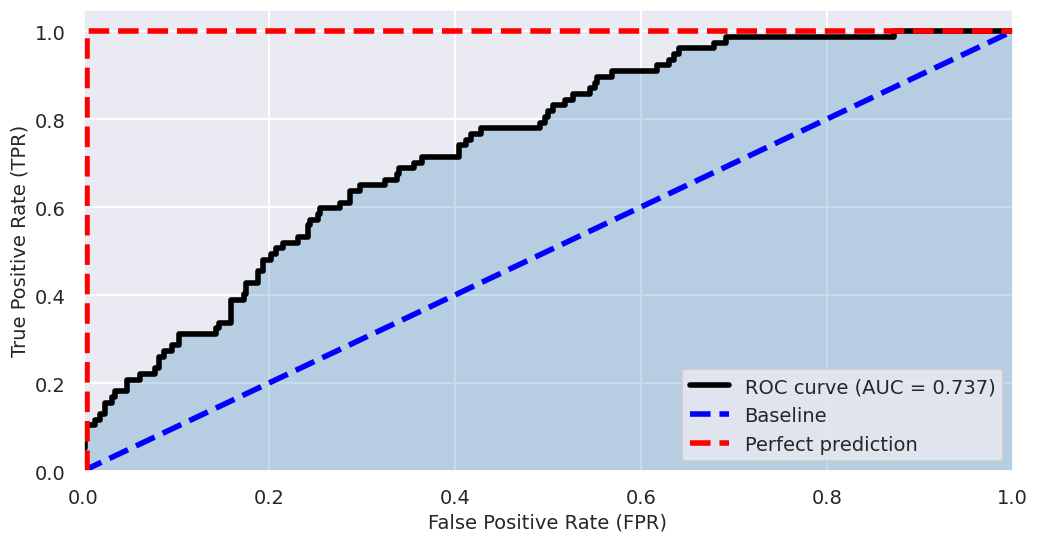

Area Under the ROC Curve (AUC): 0.737


In [9]:
fpr_roc, tpr_roc, roc_thresholds = roc_curve(mi_fchd_test["mi_fchd"], mi_fchd_test["pred_prob"])

roc_auc = auc(fpr_roc, tpr_roc)
plt.figure(figsize=(12,6))
plt.plot(fpr_roc, tpr_roc, color='black', lw=4, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.fill_between(fpr_roc,tpr_roc,alpha=0.25)
plt.plot([0, 1], [0, 1], color='blue', lw=4, linestyle='--', label='Baseline')
plt.plot([0.005, 0.005, 1], [0, 1, 1], color="red", lw=4, linestyle="--", label="Perfect prediction")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=14)
plt.ylabel('True Positive Rate (TPR)', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(loc="lower right", fontsize=14)
plt.grid(True)
plt.show()

print(f"Area Under the ROC Curve (AUC): {roc_auc:.3f}")

### Regularization

As a sensitivity analysis, perform regularization, particularly because some features are highly correlated (such as systolic blood pressure and diastolic blood pressure), or multicollinear (such as prevchd, prevap, and prevmi; or cursmoke and cigpday).

The correlation matrix shows how highly correlated some features are: diabp/sysbp, cigpday/cursmoke, glucose/diabetes, and prevchd with prevap and prevmi.

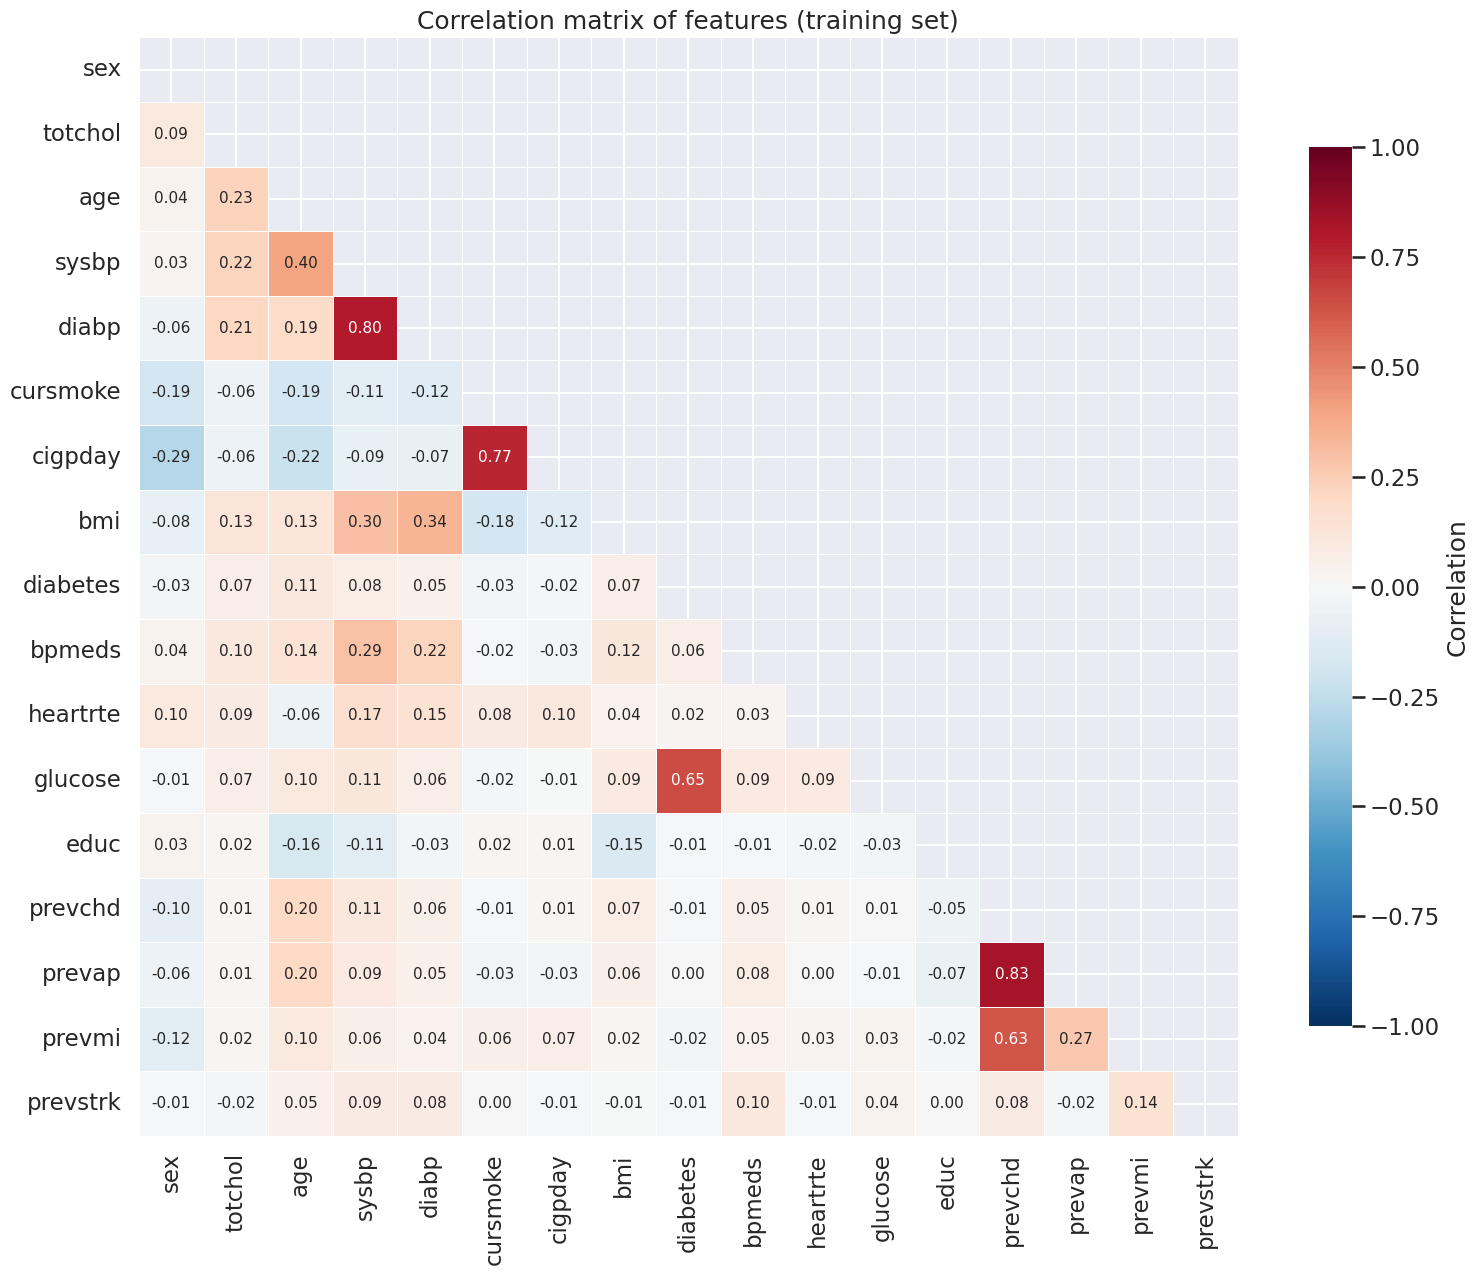

Feature pairs with |correlation| > 0.5:
prevap   prevchd     0.834
diabp    sysbp       0.797
cigpday  cursmoke    0.765
glucose  diabetes    0.651
prevmi   prevchd     0.632


In [10]:
# Correlation matrix = correlation of standardized features, comparable across features
corr_matrix = X_train.corr()

# Show only the lower triangle to avoid duplicate cells
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr_matrix, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 11},
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "Correlation"}, ax=ax)
ax.set_title("Correlation matrix of features (training set)")
plt.tight_layout()
plt.show()

# Flag highly correlated feature pairs (|r| > 0.5)
pairs = corr_matrix.where(~mask).stack()
high_corr = pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False)
print("Feature pairs with |correlation| > 0.5:")
print(high_corr.round(3).to_string())

Now evaluate AUCs for cross-validated L1 and L2 regularized models. Use StandardScaler to standardize features to the same scale.

The cross-validated AUCs are 0.751 for L1, and 0.754 for L2; given the marginal improvement with L2, for parsimony, plan to use L1 model:

In [11]:
from sklearn.linear_model import LogisticRegression

import warnings; warnings.filterwarnings("ignore")

Cs = np.logspace(-3, 2, 30)          # C = 1/λ; smaller C = stronger penalty
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def cv_auc(penalty, solver):
    scores = np.zeros((10, len(Cs)))
    for fold_i, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        Xtr, Xval = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        ytr, yval = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        for c_i, C in enumerate(Cs):
            m = make_pipeline(StandardScaler(),   # refit on each training fold
                              LogisticRegression(penalty=penalty, C=C, solver=solver, max_iter=5000))
            m.fit(Xtr, ytr)
            scores[fold_i, c_i] = roc_auc_score(yval, m.predict_proba(Xval)[:, 1])
    return scores.mean(axis=0)

cv_results = {}
for penalty, solver in [("l1", "liblinear"), ("l2", "lbfgs")]:
    mean_auc = cv_auc(penalty, solver)
    best_C = Cs[np.argmax(mean_auc)]
    final = make_pipeline(StandardScaler(),
                          LogisticRegression(penalty=penalty, C=best_C, solver=solver, max_iter=5000))
    final.fit(X_train, y_train)
    cv_results[penalty] = {"best_C": best_C, "cv_auc": mean_auc.max(), "model": final}
    print(f"{penalty.upper()}: best C={best_C:.4f} (log λ={np.log(1/best_C):.2f}), "
          f"CV AUC={mean_auc.max():.3f}")

L1: best C=0.0788 (log λ=2.54), CV AUC=0.751
L2: best C=0.0033 (log λ=5.72), CV AUC=0.754


L1 model: C = 0.0788 (selected by 10-fold stratified CV)
Features kept: 10 of 17
Features dropped: cursmoke, cigpday, bpmeds, heartrte, glucose, educ, prevstrk


,std. coef,odds ratio per 1 SD
sex,-0.402,0.669
sysbp,0.363,1.438
prevmi,0.269,1.308
prevchd,0.131,1.140
diabetes,0.125,1.134
totchol,0.117,1.124
bmi,0.110,1.116
age,0.022,1.022
prevap,0.019,1.019
diabp,0.018,1.018


Accuracy:            84.1%
True Positive Rate:  10.4%
False Positive Rate: 0.8%


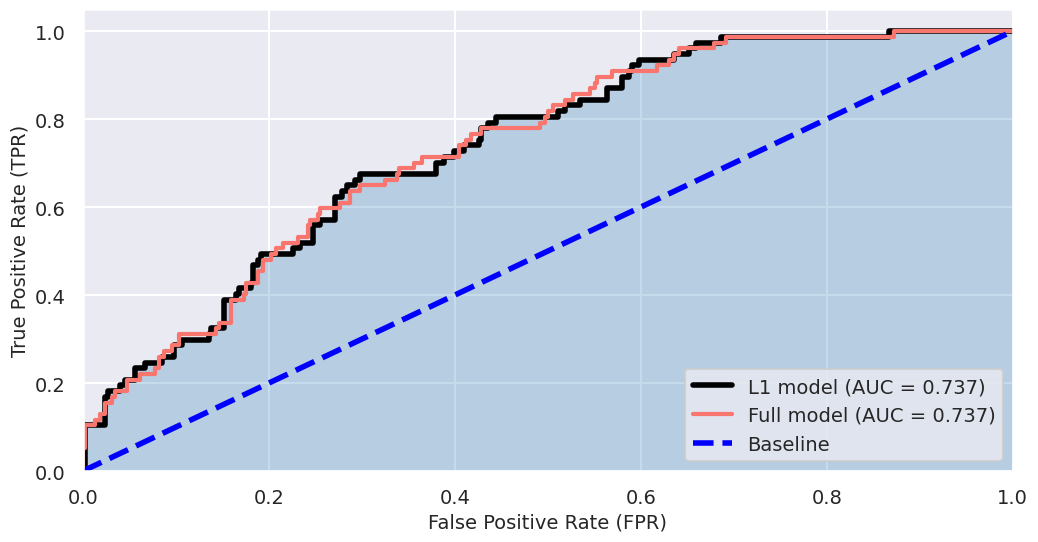

AUC (L1):   0.737
AUC (full): 0.737


In [12]:
# --- Final L1 (Lasso) logistic model, using the C chosen by 10-fold CV above ---
l1_model = cv_results["l1"]["model"]
l1_lr = l1_model[-1]
print(f"L1 model: C = {cv_results['l1']['best_C']:.4f} (selected by 10-fold stratified CV)")


# --- Model characteristics: chosen penalty and coefficients ---
l1_coefs = pd.Series(l1_lr.coef_[0], index=X_train.columns)
print(f"Features kept: {(l1_coefs != 0).sum()} of {len(l1_coefs)}")
print(f"Features dropped: {', '.join(l1_coefs[l1_coefs == 0].index) or 'none'}")
display(pd.DataFrame({
    "std. coef": l1_coefs.round(3),
    "odds ratio per 1 SD": np.exp(l1_coefs).round(3)
}).sort_values("std. coef", key=abs, ascending=False))

# --- Predictions on the test set ---
mi_fchd_test["l1_pred_prob"] = l1_model.predict_proba(X_test)[:, 1]
mi_fchd_test["l1_pred_class"] = (mi_fchd_test["l1_pred_prob"] >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(mi_fchd_test["mi_fchd"], mi_fchd_test["l1_pred_class"]).ravel()
print(f"Accuracy:            {(tp+tn)/(tn+fp+fn+tp):.1%}")
print(f"True Positive Rate:  {tp/(tp+fn):.1%}")
print(f"False Positive Rate: {fp/(fp+tn):.1%}")

# --- ROC curve: L1 vs full model ---
fpr_l1, tpr_l1, _ = roc_curve(mi_fchd_test["mi_fchd"], mi_fchd_test["l1_pred_prob"])
fpr_full, tpr_full, _ = roc_curve(mi_fchd_test["mi_fchd"], mi_fchd_test["pred_prob"])
auc_l1 = auc(fpr_l1, tpr_l1)
auc_full = auc(fpr_full, tpr_full)

plt.figure(figsize=(12, 6))
plt.plot(fpr_l1, tpr_l1, color="black", lw=4, label=f"L1 model (AUC = {auc_l1:.3f})")
plt.fill_between(fpr_l1, tpr_l1, alpha=0.25)
plt.plot(fpr_full, tpr_full, color="#F8766D", lw=3, label=f"Full model (AUC = {auc_full:.3f})")
plt.plot([0, 1], [0, 1], color="blue", lw=4, linestyle="--", label="Baseline")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)", fontsize=14)
plt.ylabel("True Positive Rate (TPR)", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(loc="lower right", fontsize=14)
plt.grid(True)
plt.show()

print(f"AUC (L1):   {auc_l1:.3f}")
print(f"AUC (full): {auc_full:.3f}")

### Model performance

The AUC achieved with this L1-regularized logistic regression model is on par with that of other models which used variants of Framingham data to generate risk prediction models:

- 0.7227 (Zhang J, Li T. Discrimination stability and calibration of cardiovascular risk prediction models in the Framingham baseline cohort. Nature Scientific Reports. 5/26/2026)
- 0.72 (Ashar J, Bangera A, et al. Predicting Ten Year Cardiovascular Risk Using Framingham Heart Study Dataset. IEEE Conference. 2026)

While the class imbalance does affect model accuracy, it does not affect AUC. Improvement in AUC would likely require inclusion of other features more predictive of hospitalized MI and fatal CHD.

### Managerial impact

The goal of this prediction model is not to achieve high accuracy, but rather to predict which patients have a high risk of hospitalized MI or fatal CHD, and should be prioritized. An application of this model is triaging patients who go to an emergency room with symptoms of a heart attack (chest pain, sweating, shortness of breath), in order to prioritize high risk patients for lab testing and rapid evaluation.

Here are some hypothetical consequences of each possible prediction outcome, in units of cost points where 0 cost points is most ideal; the units reflect relative severity of each outcome.
- True positive. Patient is flagged as high risk, and is appropriately prioritized: 50 cost points
- True negative. Patient is  flagged as low risk, and is appropriately deprioritized: 0 cost points (lowest consequence)
- False positive. Patient is flagged as high risk, and is inappropriately prioritized: 25 cost points
- False negative. Patient is flagged as low risk, and is inappropriately deprioritized: 100 cost points (highest consequence)

A decision threshold can be calculated to minimize these consequences:

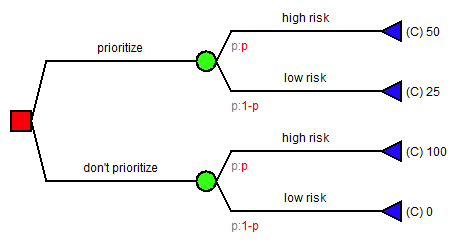

- Consequences of prioritization <= consequences of non-prioritization
- 50(p) + 25(1-p) <= 100(p) + 0(1-p)
- p >= 0.333

Now compare three decision thresholds: 0.5, 0.333, and the threshold that minimizes consequences on the training data

In [13]:
# Cost of the consequences for a set of patients at a given classification threshold (lower is better)
def consequences(y_true, probs, threshold):
    tn, fp, fn, tp = confusion_matrix(
        y_true, (probs >= threshold).astype(int), labels=[0, 1]
    ).ravel()
    return (
        0 * tn +    # low risk, deprioritized
        25 * fp +   # low risk, prioritized
        100 * fn +  # high risk, deprioritized
        50 * tp     # high risk, prioritized
    )

# Grid of candidate thresholds, named explicitly so that it is never
# confused with the thresholds returned by roc_curve()
consequences_grid = np.linspace(0, 1, 101)

# Predicted high risk probabilities from L1 model
pred_train = l1_model.predict_proba(X_train)[:, 1]
pred_test = l1_model.predict_proba(X_test)[:, 1]

train_consequences = np.array([consequences(y_train, pred_train, t) for t in consequences_grid])
test_consequences = np.array([consequences(y_test, pred_test, t) for t in consequences_grid])


# Threshold tuned on the training set
t_train = consequences_grid[train_consequences.argmin()]

# Benchmarks on the test set.
n_pos = (y_test == 1).sum()
n_neg = (y_test == 0).sum()
no_priority = 100 * n_pos                   # threshold 1: everyone deprioritized
uniform_priority = 50 * n_pos + 25 * n_neg  # threshold 0: everyone prioritized

# The three targeted decision rules
# (short name, full name, threshold)
rules = [
    ("Conventional threshold", 0.5),
    ("Implied by the payoff matrix", 1 / 3),
    ("Tuned on the training set", t_train),
]


entries = [
    ("No priority (benchmark)", 1.0, no_priority),
    ("Uniform priority (benchmark)", 0.0, uniform_priority),
] + [
    (name, threshold, consequences(y_test, pred_test, threshold))
    for name, threshold in rules
]

cost_df = pd.DataFrame([
    {
        "Rule": name,
        "Threshold": f"{threshold:.3f}",
        "Test cost (relative units)": f"{cost:,.0f}",
        "Savings vs. no priority": f"{(no_priority - cost) / no_priority:.1%}",
    }
    for name, threshold, cost in entries
])
display(cost_df)


,Rule,Threshold,Test cost (relative units),Savings vs. no priority
0,No priority (benchmark),1.000,"7,700",0.0%
1,Uniform priority (benchmark),0.000,"13,250",-72.1%
2,Conventional threshold,0.500,"7,375",4.2%
3,Implied by the payoff matrix,0.333,"7,375",4.2%
4,Tuned on the training set,0.290,"7,450",3.2%


The tuned threshold (0.29) is close to the payoff-matrix threshold (0.333), and on the test set 0.333 and 0.5 tie for the lowest cost (4.2% savings vs. no priority). The cost curve is flat between about 0.25 and 0.5, so differences between these rules amount to a few patients and are within sampling noise. I use 0.333 because it follows directly from the payoff matrix.

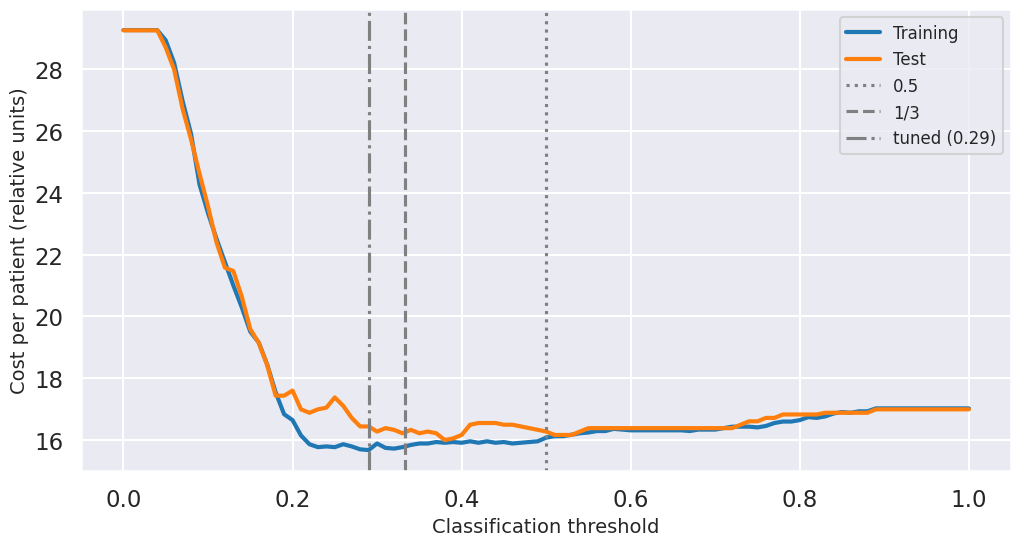

In [14]:
plt.figure(figsize=(12, 6))
plt.plot(consequences_grid, train_consequences / len(y_train), lw=3, label="Training")
plt.plot(consequences_grid, test_consequences / len(y_test), lw=3, label="Test")
for t, ls, lab in [(0.5, ":", "0.5"), (1/3, "--", "1/3"), (t_train, "-.", f"tuned ({t_train:.2f})")]:
    plt.axvline(t, color="gray", ls=ls, label=lab)
plt.xlabel("Classification threshold", fontsize=14)
plt.ylabel("Cost per patient (relative units)", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

# Integrating EKG data to enhance prediction

When patients in the emergency room describe symptoms consistent with a heart attack (chest pain, sweating, shortness of breath), an EKG is typically obtained. Therefore, in addition to historical data used as features in the logistic regression prediction model, unstructured EKG data can also be used as another feature to predict heart attack, and therefore expedite high-risk patients. Of note, EKG alone is not diagnostic of a heart attack; other tests such as serum troponin, echocardiography, and coronary angiography are also important in the diagnosis, and so expediting these tests other in high-risk patients is an opportunity for prediction modeling.

To enhance this model, I integrate EKG data using CNN. Subsequent sections of this notebook should be run in Google Colab. See README.txt for details.

### The PTB-XL dataset

From ([PhysioNet](https://physionet.org/content/ptb-xl/1.0.3/)): "PTB-XL ECG dataset is a large dataset of 21799 clinical 12-lead ECGs from 18869 patients of 10 second length. The raw waveform data was annotated by up to two cardiologists, who assigned potentially multiple ECG statements to each record." Each EKG was labeled with one or more class labels: normal (NORM), myocardial infarction (MI), ST/T change (STTC), conduction disturbance (CD), and hypertrophy (HYP). 411 EKGs without a class label were excluded. 

- **Target**: `mi` = 1 if any of the EKG's diagnostic statements belongs to the MI class, 0 otherwise.
- **Signal (unstructured data)**: the 100 Hz version, so each EKG is an array of 1,000 time steps by 12 leads.
- **Tabular features**: age and sex. Height and weight are missing for most records, so they are not used.
- **Split**: PTB-XL provides 10 stratified folds in which all EKGs from one patient fall in the same fold. Following the dataset authors' recommendation, folds 1 to 8 are training, fold 9 is validation (used for early stopping), and fold 10 is the test set. Splitting by patient prevents the model from being tested on a patient it has already seen.

**Framing.** PTB-XL labels indicate whether a cardiologist read MI on this EKG. The Framingham target mi_fchd is a prediction of MI or fatal CHD in the next 8 years. The EKG model complements the Framingham data in the emergency room triage setting described above, and flags patients whose EKG already shows MI.

Three models are compared on the same held-out test set:
1. **Tabular only**: logistic regression on age and sex, the same family of model used for the Framingham data
2. **EKG only**: a 1D convolutional neural network on the raw EKG signal
3. **Fused**: the CNN's learned EKG representation combined with age and sex

In [15]:
%pip install -q wfdb

import zipfile
from urllib.request import urlretrieve
import wfdb
import tensorflow as tf
import keras
from keras import layers
from tqdm.auto import tqdm

SEED = 1234
keras.utils.set_random_seed(SEED)

print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}")
gpus = tf.config.list_physical_devices("GPU")
print(f"GPUs available: {gpus}")
if not gpus:
    print("WARNING: no GPU found. Training will be very slow. In Colab: Runtime > Change runtime type > T4 GPU.")

# Parsed signals and metadata are cached next to the notebook (in Colab: the Google Drive folder)
SIGNALS_CACHE = os.path.join(PROJECT_DIR, "ptbxl_signals_100hz.npy")
META_CACHE = os.path.join(PROJECT_DIR, "ptbxl_meta.csv")
# Raw download goes to fast local disk in Colab, or to a subfolder locally
RAW_DIR = "/content/ptbxl_raw" if IN_COLAB else os.path.join(PROJECT_DIR, "ptbxl_raw")

Keras 3.13.2, backend: tensorflow
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
DATA_URL = ("https://physionet.org/static/published-projects/ptb-xl/"
            "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip")

if os.path.exists(SIGNALS_CACHE) and os.path.exists(META_CACHE):
    # Fast path: load the arrays parsed on a previous run
    meta = pd.read_csv(META_CACHE, index_col="ecg_id")
    ecg_X = np.load(SIGNALS_CACHE)
    print("Loaded cached PTB-XL data")
else:
    # Download the dataset
    os.makedirs(RAW_DIR, exist_ok=True)
    zip_path = os.path.join(RAW_DIR, "ptbxl.zip")
    with tqdm(unit="B", unit_scale=True, desc="Downloading PTB-XL") as bar:
        def report(blocks, block_size, total):
            bar.total = total
            bar.update(blocks * block_size - bar.n)
        urlretrieve(DATA_URL, zip_path, reporthook=report)

    # Extract only the metadata and the 100 Hz signals
    with zipfile.ZipFile(zip_path) as zf:
        names = zf.namelist()
        wanted = [n for n in names if n.endswith(("ptbxl_database.csv", "scp_statements.csv")) or "/records100/" in n]
        zf.extractall(RAW_DIR, members=wanted)
    data_dir = os.path.join(RAW_DIR, os.path.dirname(next(n for n in names if n.endswith("ptbxl_database.csv"))))
    os.remove(zip_path)

    meta = pd.read_csv(os.path.join(data_dir, "ptbxl_database.csv"), index_col="ecg_id")
    meta["scp_codes"] = meta["scp_codes"].apply(ast.literal_eval)

    # Map each diagnostic SCP statement to its superclass
    scp = pd.read_csv(os.path.join(data_dir, "scp_statements.csv"), index_col=0)
    scp = scp[scp["diagnostic"] == 1]

    def superclasses(codes):
        return sorted({scp.loc[c, "diagnostic_class"] for c in codes if c in scp.index})

    meta["superclass"] = meta["scp_codes"].apply(superclasses)
    meta = meta[meta["superclass"].map(len) > 0]     # drop EKGs without a diagnostic statement
    meta["mi"] = meta["superclass"].apply(lambda s: int("MI" in s))
    meta["superclass"] = meta["superclass"].apply(",".join)

    # Read every 100 Hz record: shape (n_ekgs, 1000 time steps, 12 leads)
    ecg_X = np.stack([wfdb.rdsamp(os.path.join(data_dir, f))[0]
                      for f in tqdm(meta["filename_lr"], desc="Reading EKGs")]).astype(np.float16)

    meta = meta[["patient_id", "age", "sex", "strat_fold", "superclass", "mi"]]
    meta.to_csv(META_CACHE)
    np.save(SIGNALS_CACHE, ecg_X)
    print("Saved parsed PTB-XL data")

print("Signals:", ecg_X.shape)
display(meta.head())

Reading EKGs:   0%|          | 0/21388 [00:00<?, ?it/s]

Saved parsed PTB-XL data
Signals: (21388, 1000, 12)


,patient_id,age,sex,strat_fold,superclass,mi
ecg_id,,,,,,
1,15709.0,56.0,1,3,NORM,0
2,13243.0,19.0,0,2,NORM,0
3,20372.0,37.0,1,5,NORM,0
4,17014.0,24.0,0,3,NORM,0
5,17448.0,19.0,1,4,NORM,0


### Exploratory data analysis of EKGs

About 25% of PTB-XL EKGs show MI, a higher prevalence than the 17% outcome rate in the Framingham data. The MI prevalence is similar across the training, validation, and test folds, since the folds are stratified.

In [17]:
# Ages above 89 are recorded as 300 in PTB-XL for anonymization
meta["age"] = meta["age"].clip(upper=90)

ecg_split = pd.cut(meta["strat_fold"], bins=[0, 8, 9, 10],
                   labels=["Train (folds 1-8)", "Validation (fold 9)", "Test (fold 10)"])
split_summary = meta.groupby(ecg_split, observed=True).agg(
    EKGs=("mi", "size"), MI_cases=("mi", "sum"), MI_rate=("mi", "mean"))
split_summary["MI_rate"] = split_summary["MI_rate"].map("{:.1%}".format)
display(split_summary)

,EKGs,MI_cases,MI_rate
strat_fold,,,
Train (folds 1-8),17084,4379,25.6%
Validation (fold 9),2146,540,25.2%
Test (fold 10),2158,550,25.5%


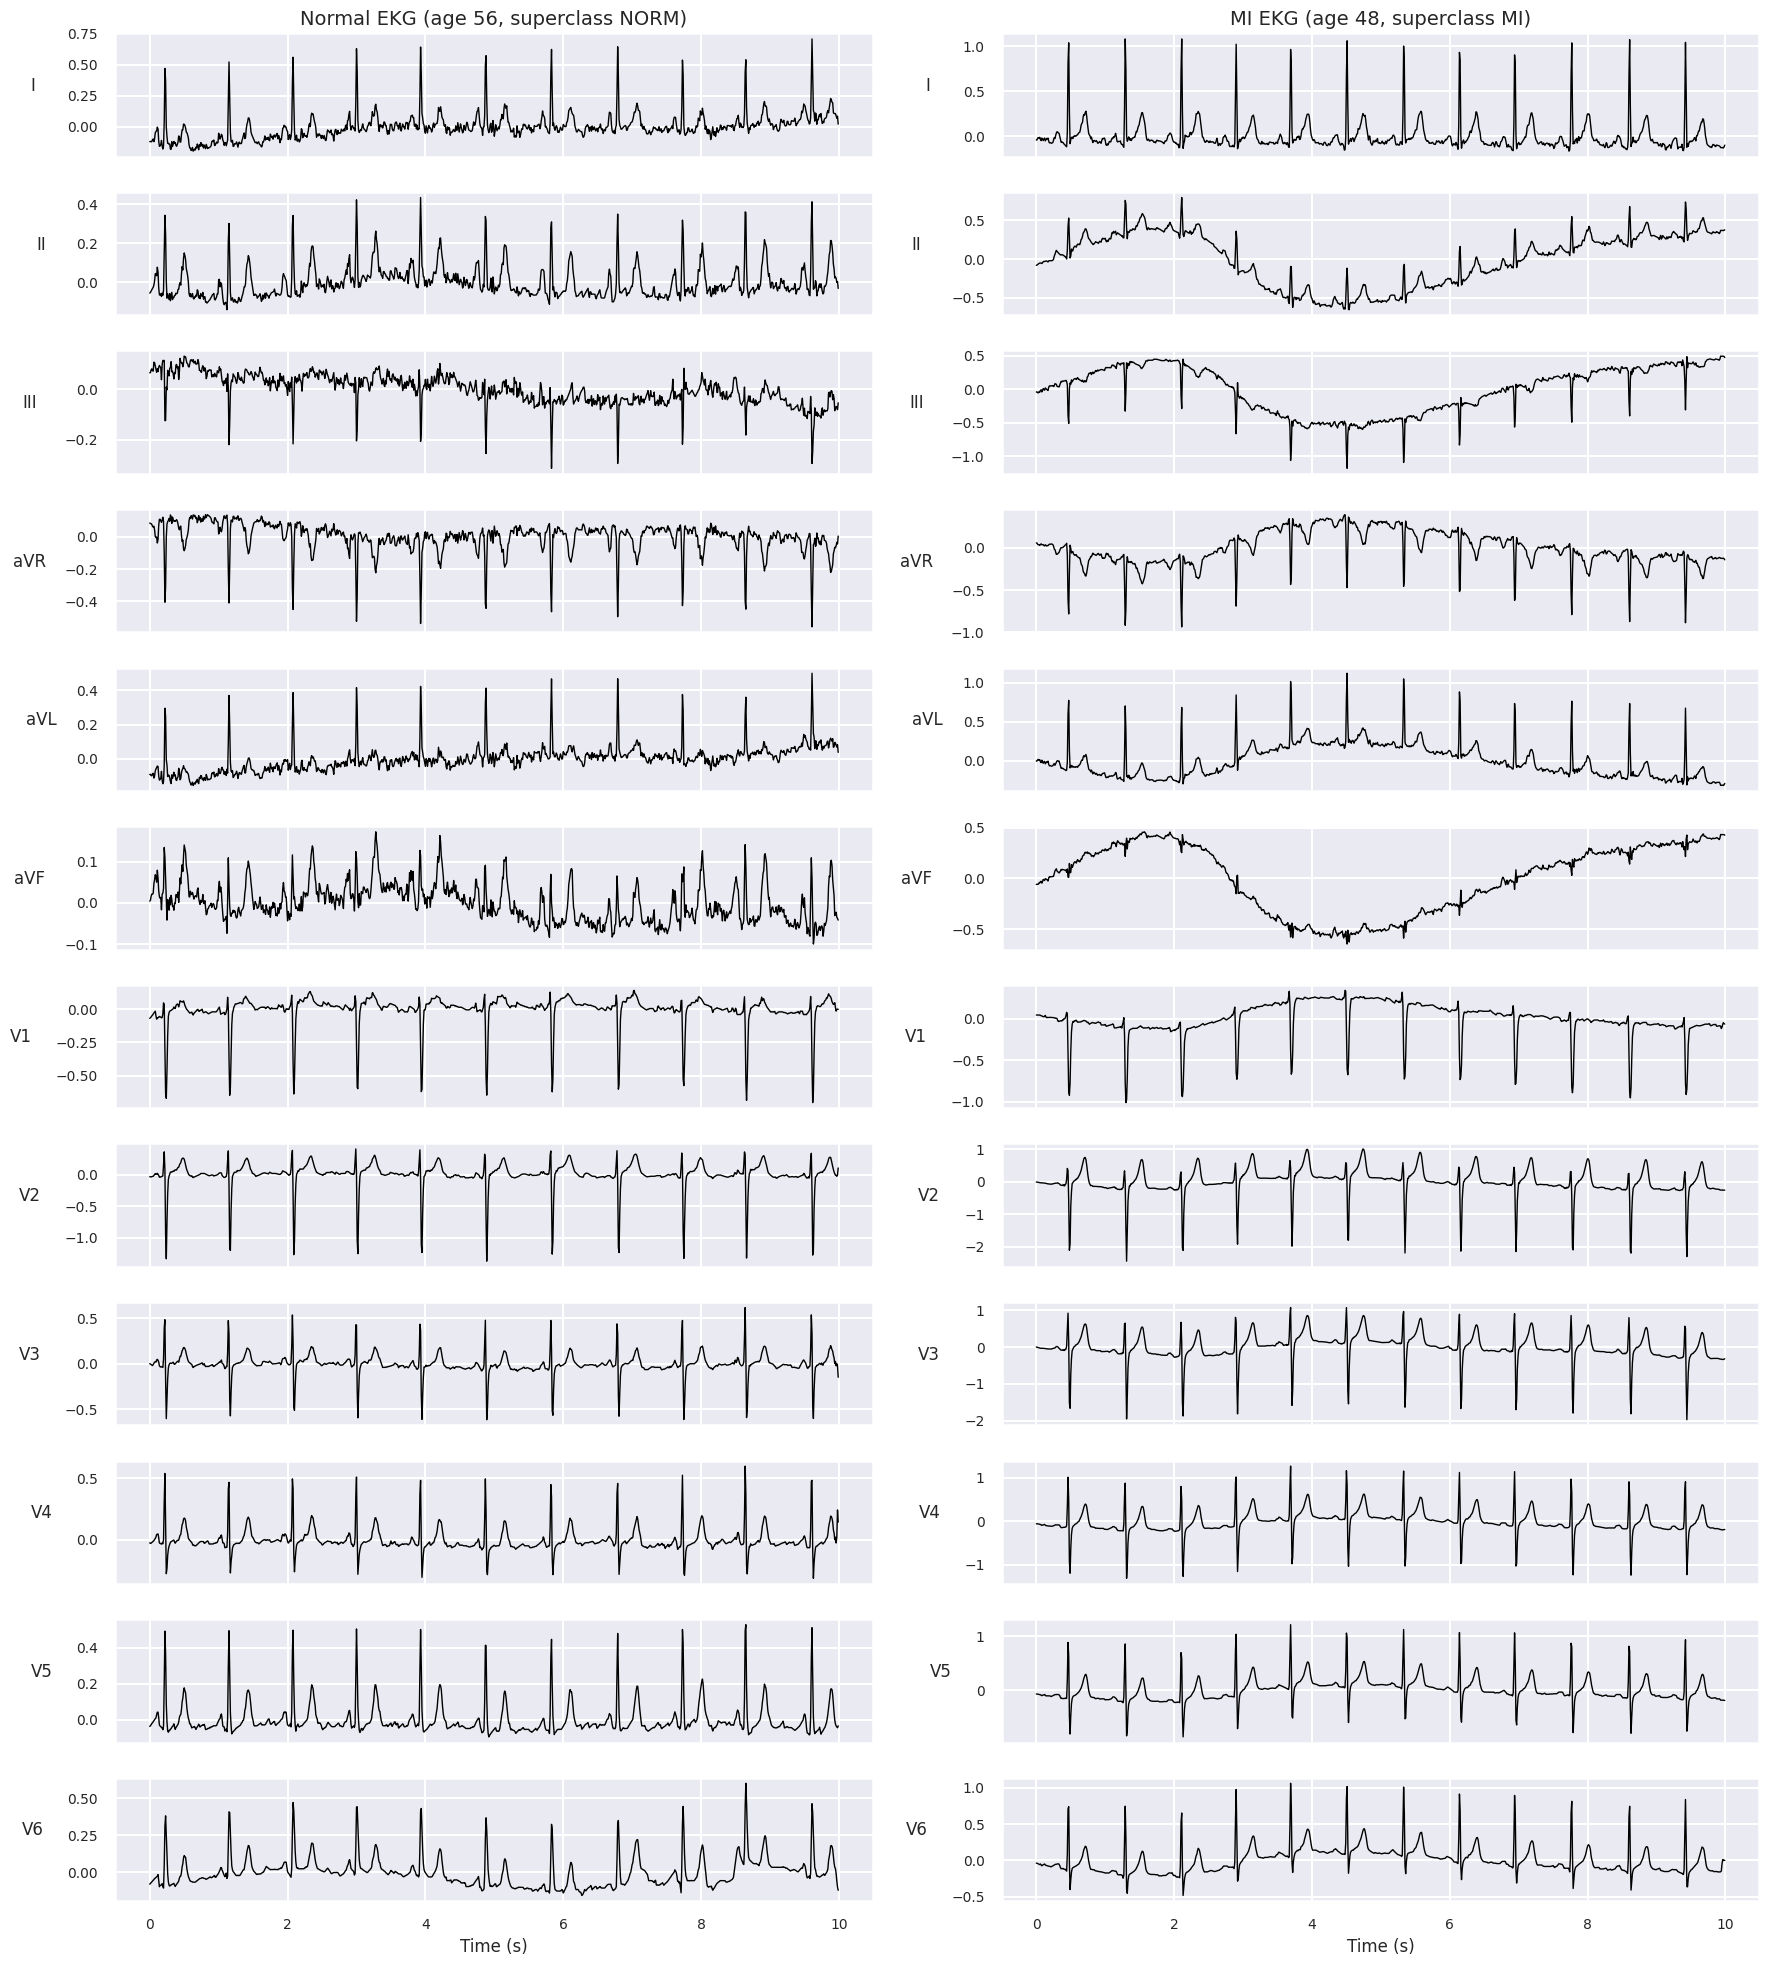

In [18]:
# One normal EKG and one MI EKG, all 12 leads
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
seconds = np.arange(1000) / 100

examples = {
    "Normal EKG": np.where((meta["superclass"] == "NORM").values)[0][0],
    "MI EKG": np.where((meta["mi"] == 1).values)[0][0],
}

fig, axes = plt.subplots(12, 2, figsize=(18, 20), sharex=True)
for col, (title, i) in enumerate(examples.items()):
    for lead in range(12):
        ax = axes[lead, col]
        ax.plot(seconds, ecg_X[i, :, lead].astype(np.float32), color="black", lw=1)
        ax.set_ylabel(LEADS[lead], rotation=0, labelpad=25, fontsize=12)
        ax.tick_params(labelsize=10)
    axes[0, col].set_title(f"{title} (age {meta['age'].iloc[i]:.0f}, superclass {meta['superclass'].iloc[i]})",
                           fontsize=14)
    axes[-1, col].set_xlabel("Time (s)", fontsize=12)
plt.tight_layout()
plt.show()

### EKG training, validation, and test split; preprocessing

Each lead is standardized using the mean and standard deviation computed on the training folds only, so no information from the validation or test sets leaks into training. Age and sex are standardized the same way, and missing ages are imputed with the training median. Variables in this section are prefixed (`Xe_`, `ye_`, `T_`) so they do not overwrite the Framingham `X_train`, `y_train`, etc.

In [19]:
is_train = (meta["strat_fold"] <= 8).values
is_val = (meta["strat_fold"] == 9).values
is_test = (meta["strat_fold"] == 10).values

ye = meta["mi"].values
ye_train, ye_val, ye_test = ye[is_train], ye[is_val], ye[is_test]

# EKG signals: per-lead standardization with training statistics
Xe_train = ecg_X[is_train].astype(np.float32)
lead_mean = Xe_train.mean(axis=(0, 1))
lead_std = Xe_train.std(axis=(0, 1))
Xe_train = (Xe_train - lead_mean) / lead_std
Xe_val = (ecg_X[is_val].astype(np.float32) - lead_mean) / lead_std
Xe_test = (ecg_X[is_test].astype(np.float32) - lead_mean) / lead_std

# Tabular features: age and sex (PTB-XL codes sex as 0 = male, 1 = female)
tab = meta[["age", "sex"]].copy()
tab["age"] = tab["age"].fillna(tab.loc[is_train, "age"].median())
tab_scaler = StandardScaler().fit(tab[is_train])
T_train, T_val, T_test = (tab_scaler.transform(tab[m]).astype(np.float32) for m in (is_train, is_val, is_test))

print("Train:", Xe_train.shape, " Validation:", Xe_val.shape, " Test:", Xe_test.shape)

Train: (17084, 1000, 12)  Validation: (2146, 1000, 12)  Test: (2158, 1000, 12)


### Model 1: tabular-only logistic regression (baseline)

MI can be predicted from patient age and sex with an AUC of 0.70:

In [20]:
tab_model = LogisticRegression().fit(T_train, ye_train)
p_tab_val = tab_model.predict_proba(T_val)[:, 1]
p_tab_test = tab_model.predict_proba(T_test)[:, 1]
print(f"Tabular-only test AUC: {roc_auc_score(ye_test, p_tab_test):.3f}")

Tabular-only test AUC: 0.698


### Models 2 and 3: 1D convolutional neural network

The CNN reads the raw EKG as a sequence of 1,000 time steps with 12 channels (one per lead). Four convolutional blocks each apply 1D convolutions (kernel width 7, i.e. 70 ms), batch normalization, a ReLU activation, and max pooling, which halves the time dimension. Early blocks detect short local shapes such as QRS complexes; later blocks combine them into longer patterns such as pathological Q waves or ST elevation. Global average pooling then summarizes the whole recording into a fixed-length **representation** vector.

- **EKG only**: the representation feeds a small dense classification head.
- **Fused**: age and sex are concatenated to the representation before the classification head, so the network can combine what it learned from the signal with the patient's demographics.

Training uses binary cross-entropy, the Adam optimizer, and early stopping on validation AUC (restoring the best weights), which guards against overfitting.

In [21]:
def build_cnn(use_tab):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    ekg = layers.Input(shape=(1000, 12), name="ekg")
    x = ekg
    for n_filters in [32, 64, 128, 128]:
        x = layers.Conv1D(n_filters, 7, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(2)(x)
    representation = layers.GlobalAveragePooling1D()(x)

    inputs = [ekg]
    if use_tab:
        demographics = layers.Input(shape=(2,), name="age_sex")
        representation = layers.Concatenate()([representation, demographics])
        inputs.append(demographics)

    x = layers.Dropout(0.3)(representation)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    probability = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, probability)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


def cnn_inputs(Xe_part, T_part, use_tab):
    return [Xe_part, T_part] if use_tab else Xe_part


def train_cnn(use_tab):
    model = build_cnn(use_tab)
    history = model.fit(cnn_inputs(Xe_train, T_train, use_tab), ye_train,
                        validation_data=(cnn_inputs(Xe_val, T_val, use_tab), ye_val),
                        epochs=40, batch_size=128, verbose=2,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                                                 restore_best_weights=True)])
    return model, history


build_cnn(use_tab=True).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ekg (InputLayer)    │ (None, 1000, 12)  │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1000, 32)  │      2,688 │ ekg[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1000, 32)  │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 1000, 32)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 500, 32)   │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 500, 64)   │     14,336 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 500, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 250, 64)   │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 250, 128)  │     57,344 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 128)  │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 250, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 125, 128)  │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 125, 128)  │    114,688 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 125, 128)  │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 125, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 62, 128)   │          0 │ activation_3[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling1d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 198,913 (777.00 KB)

 Trainable params: 198,209 (774.25 KB)

 Non-trainable params: 704 (2.75 KB)

For the EKG-only CNN, validation AUC is maximum at Epoch 15 (0.927), and test AUC is 0.926:

In [22]:
ekg_model, ekg_history = train_cnn(use_tab=False)
p_ekg_val = ekg_model.predict(Xe_val, batch_size=512, verbose=0).ravel()
p_ekg_test = ekg_model.predict(Xe_test, batch_size=512, verbose=0).ravel()
print(f"EKG-only test AUC: {roc_auc_score(ye_test, p_ekg_test):.3f}")

Epoch 1/40
134/134 - 84s - 629ms/step - auc: 0.8428 - loss: 0.4122 - val_auc: 0.8955 - val_loss: 0.3646
Epoch 2/40
134/134 - 6s - 46ms/step - auc: 0.9051 - loss: 0.3274 - val_auc: 0.9082 - val_loss: 0.3580
Epoch 3/40
134/134 - 3s - 19ms/step - auc: 0.9185 - loss: 0.3046 - val_auc: 0.9083 - val_loss: 0.8508
Epoch 4/40
134/134 - 3s - 19ms/step - auc: 0.9268 - loss: 0.2894 - val_auc: 0.9119 - val_loss: 0.5813
Epoch 5/40
134/134 - 3s - 19ms/step - auc: 0.9359 - loss: 0.2726 - val_auc: 0.9135 - val_loss: 0.6373
Epoch 6/40
134/134 - 3s - 21ms/step - auc: 0.9391 - loss: 0.2656 - val_auc: 0.9183 - val_loss: 0.5944
Epoch 7/40
134/134 - 3s - 20ms/step - auc: 0.9430 - loss: 0.2578 - val_auc: 0.9173 - val_loss: 0.5900
Epoch 8/40
134/134 - 3s - 19ms/step - auc: 0.9472 - loss: 0.2478 - val_auc: 0.9188 - val_loss: 0.6215
Epoch 9/40
134/134 - 3s - 19ms/step - auc: 0.9498 - loss: 0.2416 - val_auc: 0.9198 - val_loss: 0.4918
Epoch 10/40
134/134 - 3s - 19ms/step - auc: 0.9526 - loss: 0.2352 - val_auc: 0.9

For the EKG and tabular fused CNN, validation AUC is maximum at Epoch 12 (0.925), and test AUC is 0.922:

In [23]:
fused_model, fused_history = train_cnn(use_tab=True)
p_fused_val = fused_model.predict([Xe_val, T_val], batch_size=512, verbose=0).ravel()
p_fused_test = fused_model.predict([Xe_test, T_test], batch_size=512, verbose=0).ravel()
print(f"Fused test AUC: {roc_auc_score(ye_test, p_fused_test):.3f}")

Epoch 1/40
134/134 - 17s - 126ms/step - auc: 0.8404 - loss: 0.4155 - val_auc: 0.8930 - val_loss: 0.3633
Epoch 2/40
134/134 - 3s - 21ms/step - auc: 0.9025 - loss: 0.3322 - val_auc: 0.9061 - val_loss: 0.3513
Epoch 3/40
134/134 - 3s - 20ms/step - auc: 0.9189 - loss: 0.3041 - val_auc: 0.9148 - val_loss: 0.3122
Epoch 4/40
134/134 - 3s - 19ms/step - auc: 0.9273 - loss: 0.2888 - val_auc: 0.9202 - val_loss: 0.3185
Epoch 5/40
134/134 - 3s - 19ms/step - auc: 0.9344 - loss: 0.2753 - val_auc: 0.9143 - val_loss: 0.5113
Epoch 6/40
134/134 - 3s - 19ms/step - auc: 0.9392 - loss: 0.2653 - val_auc: 0.9167 - val_loss: 0.4725
Epoch 7/40
134/134 - 3s - 20ms/step - auc: 0.9432 - loss: 0.2570 - val_auc: 0.9211 - val_loss: 0.4347
Epoch 8/40
134/134 - 3s - 21ms/step - auc: 0.9480 - loss: 0.2464 - val_auc: 0.9225 - val_loss: 0.3735
Epoch 9/40
134/134 - 3s - 20ms/step - auc: 0.9516 - loss: 0.2385 - val_auc: 0.9193 - val_loss: 0.4862
Epoch 10/40
134/134 - 3s - 19ms/step - auc: 0.9532 - loss: 0.2339 - val_auc: 0.9

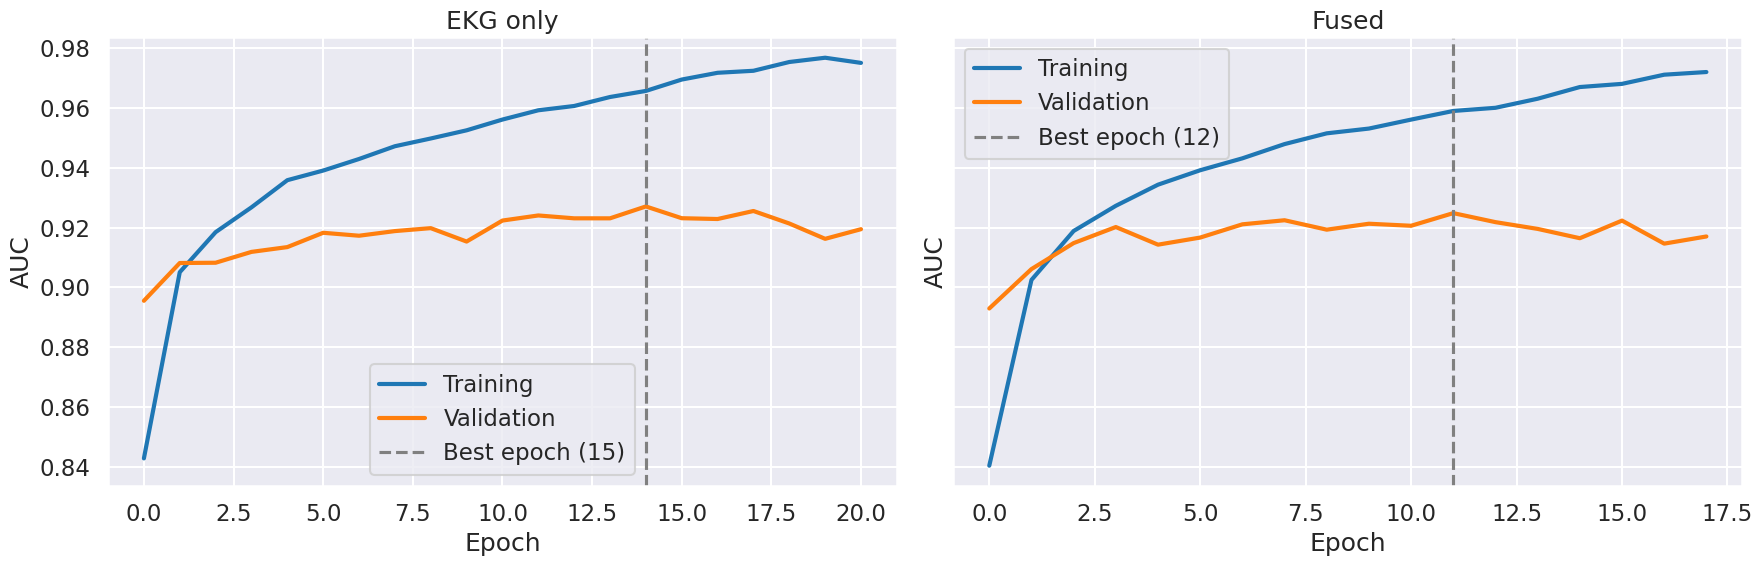

In [24]:
# Learning curves: training vs validation AUC by epoch
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for ax, (name, h) in zip(axes, [("EKG only", ekg_history), ("Fused", fused_history)]):
    ax.plot(h.history["auc"], lw=3, label="Training")
    ax.plot(h.history["val_auc"], lw=3, label="Validation")
    best = int(np.argmax(h.history["val_auc"]))
    ax.axvline(best, color="gray", ls="--", label=f"Best epoch ({best + 1})")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("AUC")
    ax.legend()
plt.tight_layout()
plt.show()

### EKG model evaluation on the test set (fold 10)

Both the EKG-only and EKG-and-tabular-fused CNNs have similar AUCs with overlapping confidence intervals, possibly because the CNN can already infer age and sex from the EKG waveform such that the tabular features do not add predictive power. For parsimony sake, I will choose the EKG-only model.

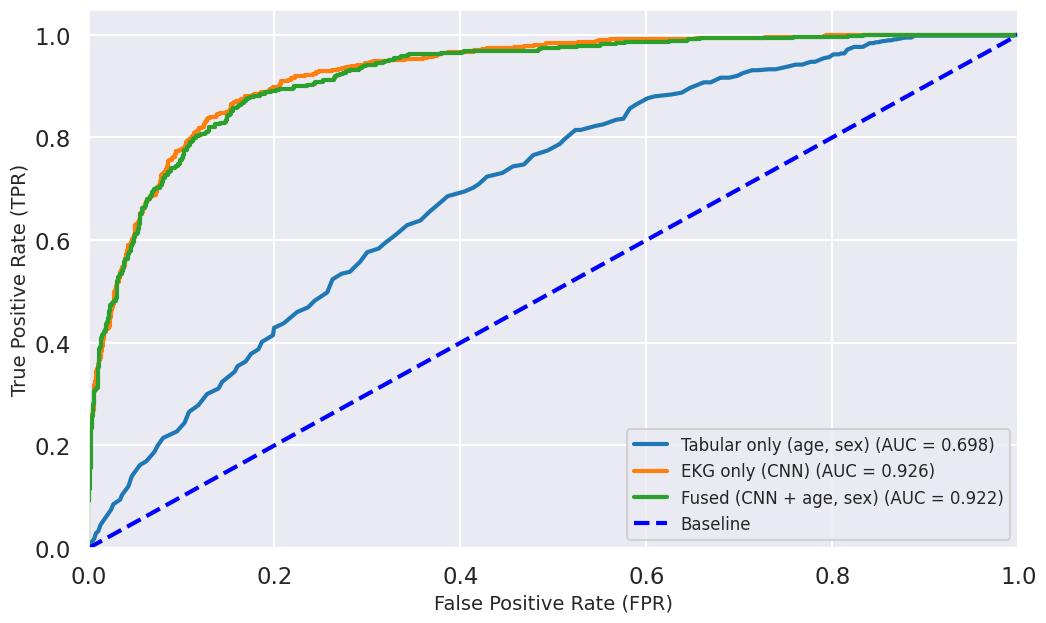

,Model,Test AUC,95% CI
0,"Tabular only (age, sex)",0.698,"[0.675, 0.722]"
1,EKG only (CNN),0.926,"[0.914, 0.937]"
2,"Fused (CNN + age, sex)",0.922,"[0.909, 0.933]"


In [25]:
def bootstrap_auc_ci(y_true, p, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() != y_true[idx].max():
            aucs.append(roc_auc_score(y_true[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


ekg_test_preds = {
    "Tabular only (age, sex)": p_tab_test,
    "EKG only (CNN)": p_ekg_test,
    "Fused (CNN + age, sex)": p_fused_test,
}

auc_rows = []
plt.figure(figsize=(12, 7))
for name, p in ekg_test_preds.items():
    auc_value = roc_auc_score(ye_test, p)
    lo, hi = bootstrap_auc_ci(ye_test, p)
    auc_rows.append({"Model": name, "Test AUC": f"{auc_value:.3f}", "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
    fpr_e, tpr_e, _ = roc_curve(ye_test, p)
    plt.plot(fpr_e, tpr_e, lw=3, label=f"{name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], color="blue", lw=3, linestyle="--", label="Baseline")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)", fontsize=14)
plt.ylabel("True Positive Rate (TPR)", fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True)
plt.show()

display(pd.DataFrame(auc_rows))

Now test various probability thresholds for when MI is predicted versus not by the EKG-only model, similar to the Framingham analysis for thresholds 0.50, 0.333 and tuned. 

All three thresholds give nearly identical test costs (37,475 to 37,575, a difference of about one missed MI), so the choice between them is within noise. I use 0.333 for consistency with the payoff matrix used in the Framingham analysis. It also has the highest sensitivity (TPR 86.9% vs. 77.6% at 0.5), at the cost of more false positives (FPR 15.9% vs. 9.8%). That trade-off suits triage, where a false negative costs four times as much as a false positive.

In [26]:
# Classification thresholds for the EKG model
EKG_THRESHOLD = 1 / 3

# Threshold tuned on the validation fold (fold 9), never on the test set
val_costs = np.array([consequences(ye_val, p_ekg_val, t) for t in consequences_grid])
t_val = consequences_grid[val_costs.argmin()]

rows = []
for name, p in [("EKG only (CNN)", p_ekg_test)]:
    for rule, t in [("Conventional", 0.5), ("Payoff matrix", EKG_THRESHOLD), ("Tuned on validation", t_val)]:
        pred_class = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(ye_test, pred_class, labels=[0, 1]).ravel()
        rows.append({"Model": name, "Rule": rule, "Threshold": f"{t:.3f}",
                     "Accuracy": f"{(tp + tn) / len(pred_class):.1%}",
                     "TPR": f"{tp / (tp + fn):.1%}", "FPR": f"{fp / (fp + tn):.1%}",
                     "Test cost": f"{consequences(ye_test, p, t):,}"})
display(pd.DataFrame(rows))


,Model,Rule,Threshold,Accuracy,TPR,FPR,Test cost
0,EKG only (CNN),Conventional,0.500,87.0%,77.6%,9.8%,"37,575"
1,EKG only (CNN),Payoff matrix,0.333,84.8%,86.9%,15.9%,"37,500"
2,EKG only (CNN),Tuned on validation,0.470,86.7%,79.5%,10.8%,"37,475"


In [27]:
# Save the trained networks and the predictions (in Colab: to the Google Drive folder)
ekg_model.save(os.path.join(PROJECT_DIR, "ekg_cnn.keras"))
fused_model.save(os.path.join(PROJECT_DIR, "fused_cnn.keras"))

ekg_preds = pd.concat([
    pd.DataFrame({"split": "validation", "ecg_id": meta.index[is_val], "mi": ye_val,
                  "p_tab": p_tab_val, "p_ekg": p_ekg_val, "p_fused": p_fused_val}),
    pd.DataFrame({"split": "test", "ecg_id": meta.index[is_test], "mi": ye_test,
                  "p_tab": p_tab_test, "p_ekg": p_ekg_test, "p_fused": p_fused_test}),
])
ekg_preds.to_csv(os.path.join(PROJECT_DIR, "ptbxl_predictions.csv"), index=False)
print(f"Saved models and {len(ekg_preds)} predictions to {PROJECT_DIR}")

Saved models and 4304 predictions to /content/drive/MyDrive/15.071_project1


# Unifying two prediction streams, limitations, and summary

Because there is no linkage between patients in Framingham tabular and PhysioNet EKG data streams, fusion in the multimodal sense is not possible. Additionally, the data sets predict slightly different outcomes, with Framingham predicting risk of hospitalized MI or fatal CHD within 8 years, and EKG predicting electrocardiographic myocardial infarction.

However I propose a system that still combines the data streams to guide triage decisions, with a two step methodology:
1) Using the logistic regression model `l1_model` based on Framingham data, the electronic medical record calculates a predicted probability of hospitalized MI or fatal CHD. At any probability above 0.333, the patient is triaged as high-priority for heart attack evaluation, including obtaining EKG. Of note, EKGs are routinely obtained for all chest pain patients, but this prediction for high-priority triage can encourage more rapid EKG evaluation. Patients who do not meet the prediction threshold of 0.333 remain on the emergency room standard pathway.
2) Once the EKG is obtained, using the CNN model `ekg_model` based on PhysioNet EKGs, the electronic medical record calculates a predicted probability of MI. At any probability above 0.333, the patient is triaged as high-priority for heart attack evaluation regardless of Step 1 classification, including serum troponin, echocardiography, and angiography. If the probability of MI is below 0.333 and the patient was classified as high-priority in Step 1, the patient maintains their high-priority triage, given the consequences of a false negative.

A limitation of this proposal is that each model is validated on its own data, but the combined two step methodology cannot be validated since tabular Framingham data and EKG data are not linked. Future work can utilize linked datasets, such as from MIMIC-IV, to develop end-to-end or fused prediction models. A couple other limitations include:
- Framingham data reflects risk over an 8 year follow up period in community-dwelling adults, not acute heart attack risk in the emergency room
- Due to missing values, 13% of Framingham data were excluded
- The EKG label of MI includes old MIs on EKG, not just acute MIs

In summary, key takeaway figures from this project are as follows:
- Framingham L1 logistic regression AUC 0.737, prediction threshold 0.333
- EKG CNN AUC 0.926, prediction threshold 0.333